# 05 · Store and answer

This notebook saves your final table in `data/processed/` as Parquet or SQLite, and writes the data dictionary to
`data/processed/DATA_DICTIONARY.md`. It also makes the chart that answers your question.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

INTERIM = Path("../data/interim")
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

In [2]:
checked = pd.read_parquet(INTERIM / "checked.parquet")
checked.head()

,country_code,alpha2,country,year,share_price_index,inflation_pct


In [3]:
start = checked[checked["year"] == 2014].set_index("country_code")["share_price_index"]
end = checked[checked["year"] == 2024].set_index("country_code")["share_price_index"]

after_2014 = checked[checked["year"] >= 2015].copy()
after_2014["price_factor"] = 1 + after_2014["inflation_pct"] / 100
prices = after_2014.groupby("country_code")["price_factor"].prod()

returns = pd.DataFrame({
    "country": checked.drop_duplicates("country_code").set_index("country_code")["country"],
    "share_growth_pct": (end / start - 1) * 100,
    "inflation_total_pct": (prices - 1) * 100,
    "real_return_pct": ((end / start) / prices - 1) * 100,
})
returns["beat_inflation"] = returns["real_return_pct"] > 0
returns = returns.sort_values("real_return_pct", ascending=False).reset_index()
returns.round(1)

,country_code,country,share_growth_pct,inflation_total_pct,real_return_pct,beat_inflation


In [4]:
checked.to_parquet(PROCESSED / "shares_and_inflation.parquet", index=False)
returns.to_parquet(PROCESSED / "real_returns.parquet", index=False)

pd.read_parquet(PROCESSED / "real_returns.parquet").dtypes

country_code               str
country                    str
share_growth_pct       float64
inflation_total_pct    float64
real_return_pct        float64
beat_inflation            bool
dtype: object

In [5]:
dictionary = pd.DataFrame([
    {"table": "shares_and_inflation", "column": "country_code", "type": "text", "meaning": "ISO 3166-1 three-letter country code", "source": "OECD"},
    {"table": "shares_and_inflation", "column": "alpha2", "type": "text", "meaning": "ISO 3166-1 two-letter country code", "source": "Wikipedia"},
    {"table": "shares_and_inflation", "column": "country", "type": "text", "meaning": "country name", "source": "World Bank"},
    {"table": "shares_and_inflation", "column": "year", "type": "whole number", "meaning": "calendar year, 2014 to 2024", "source": "OECD"},
    {"table": "shares_and_inflation", "column": "share_price_index", "type": "number", "meaning": "average level of the country's share price index in that year, in local currency, without dividends", "source": "OECD"},
    {"table": "shares_and_inflation", "column": "inflation_pct", "type": "number", "meaning": "consumer price inflation in that year, in percent", "source": "World Bank"},
    {"table": "real_returns", "column": "country_code", "type": "text", "meaning": "ISO 3166-1 three-letter country code", "source": "OECD"},
    {"table": "real_returns", "column": "country", "type": "text", "meaning": "country name", "source": "World Bank"},
    {"table": "real_returns", "column": "share_growth_pct", "type": "number", "meaning": "change of the share price index from 2014 to 2024, in percent", "source": "calculated"},
    {"table": "real_returns", "column": "inflation_total_pct", "type": "number", "meaning": "rise in consumer prices from 2014 to 2024, in percent", "source": "calculated"},
    {"table": "real_returns", "column": "real_return_pct", "type": "number", "meaning": "share price growth after inflation, in percent", "source": "calculated"},
    {"table": "real_returns", "column": "beat_inflation", "type": "true/false", "meaning": "True if real_return_pct is above zero", "source": "calculated"},
])

text = "# Data dictionary\n\n"
text += "Two tables in `data/processed/`. `shares_and_inflation.parquet` has one row per country and year. "
text += "`real_returns.parquet` has one row per country.\n\n"
text += dictionary.to_markdown(index=False) + "\n"

(PROCESSED / "DATA_DICTIONARY.md").write_text(text, encoding="utf-8")
dictionary

,table,column,type,meaning,source
0,shares_and_inflation,country_code,text,ISO 3166-1 three-letter country code,OECD
1,shares_and_inflation,alpha2,text,ISO 3166-1 two-letter country code,Wikipedia
2,shares_and_inflation,country,text,country name,World Bank
3,shares_and_inflation,year,whole number,"calendar year, 2014 to 2024",OECD
4,shares_and_inflation,share_price_index,number,average level of the country's share price ind...,OECD
5,shares_and_inflation,inflation_pct,number,"consumer price inflation in that year, in percent",World Bank
6,real_returns,country_code,text,ISO 3166-1 three-letter country code,OECD
7,real_returns,country,text,country name,World Bank
8,real_returns,share_growth_pct,number,change of the share price index from 2014 to 2...,calculated
9,real_returns,inflation_total_pct,number,"rise in consumer prices from 2014 to 2024, in ...",calculated


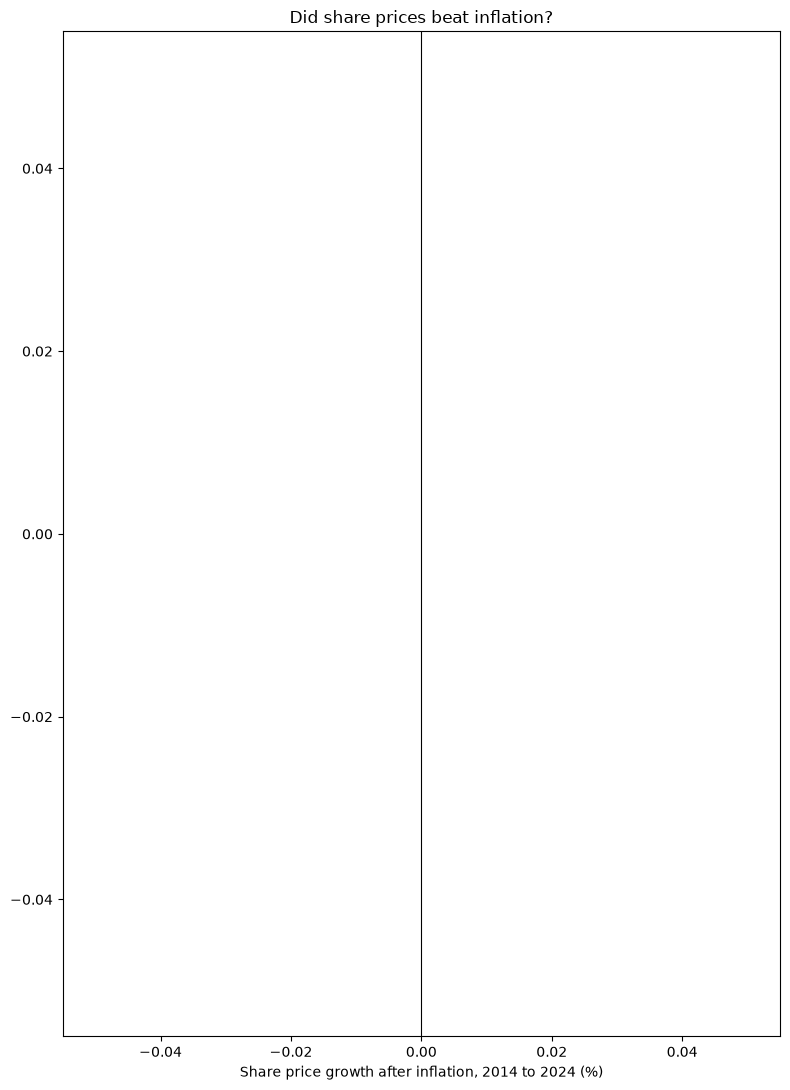

In [6]:
plot = returns.sort_values("real_return_pct")
colors = ["tab:green" if beat else "tab:red" for beat in plot["beat_inflation"]]

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(plot["country"], plot["real_return_pct"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Share price growth after inflation, 2014 to 2024 (%)")
ax.set_title("Did share prices beat inflation?")
fig.tight_layout()
fig.savefig(PROCESSED / "real_returns.png", dpi=150)
plt.show()

In [7]:
n = len(returns)
winners = returns["beat_inflation"].sum()
best = returns.iloc[0]
worst = returns.iloc[-1]

print(f"Share prices beat inflation in {winners} of {n} countries.")
print(f"Best: {best['country']} ({best['real_return_pct']:.0f}%). Worst: {worst['country']} ({worst['real_return_pct']:.0f}%).")
print(f"Median real return: {returns['real_return_pct'].median():.0f}%")

IndexError: single positional indexer is out-of-bounds

In [ ]:
returns[returns["country_code"].isin(["DEU", "USA", "GBR", "JPN", "TUR"])].round(1)